# 01 — Gamma-or-Skip Policy Preview

Apply this version's offline policy to a fixed random sample of calibration originals to inspect routing, per-image cost and before/after pixels. Nothing is exported, trained or tuned here.

**Inputs:** v1.yaml (this folder), the shared split table and original calibration images.

**Outputs:** In-memory tables and figures only.

**Prerequisites:** Original BDD sources under the shared data_root. No upstream notebook is executed.

**Outline**

- [1. Configuration](#section-1)
- [2. Policy on Calibration Samples](#section-2)
- [3. Policy Summary](#section-3)

<a id="section-1"></a>

## 1. Configuration

Change SAMPLES/SHOW freely; policy parameters live only in the version YAML.

In [1]:
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from vehicle_detection.common import project_root, read_image, require_paths
from vehicle_detection.experiment_data import load_experiment, shared_splits
from vehicle_detection.preprocess import apply_recipe

ROOT = project_root()
os.chdir(ROOT)  # Run All behaves the same from any kernel working directory.
EXPERIMENT = "v1"
require_paths(
    config=ROOT / f"notebooks/experiments/{EXPERIMENT}/{EXPERIMENT}.yaml",
    shared=ROOT / "configs/data.yaml",
)
config = load_experiment(ROOT, EXPERIMENT)

SAMPLES = 64
SHOW = 4
shared, rows = shared_splits(ROOT)
data_root = ROOT / shared["data_root"]
require_paths(data_root=data_root)

<a id="section-2"></a>

## 2. Policy on Calibration Samples

Features are measured on the original pixels; only the routed operator changes the image.

,images,ms,brightness,contrast
applied,,,,
,41,2.124877,0.324362,0.228915
gamma,23,4.679718,0.075865,0.088903


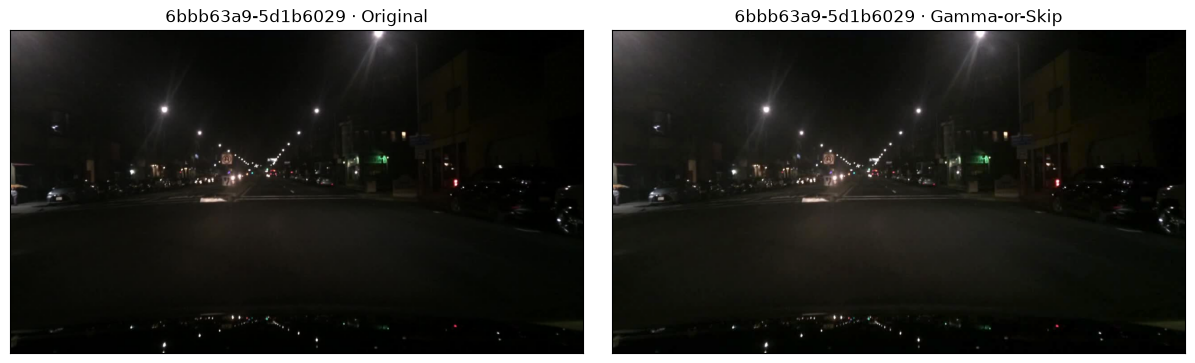

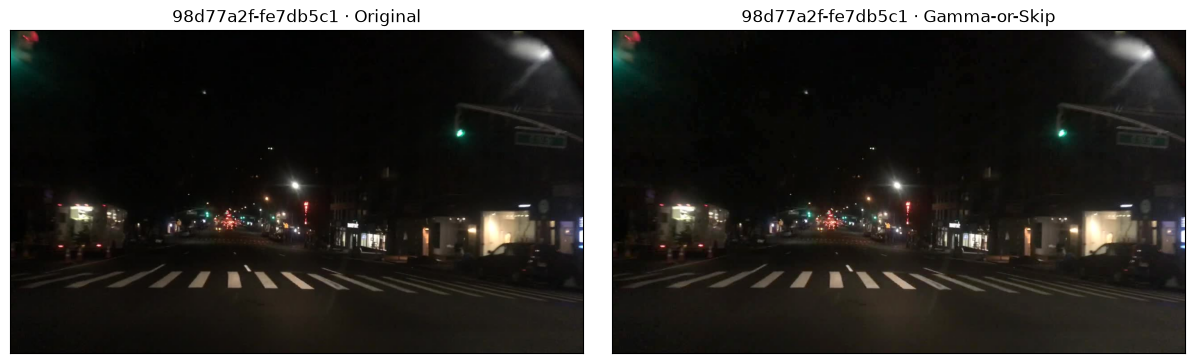

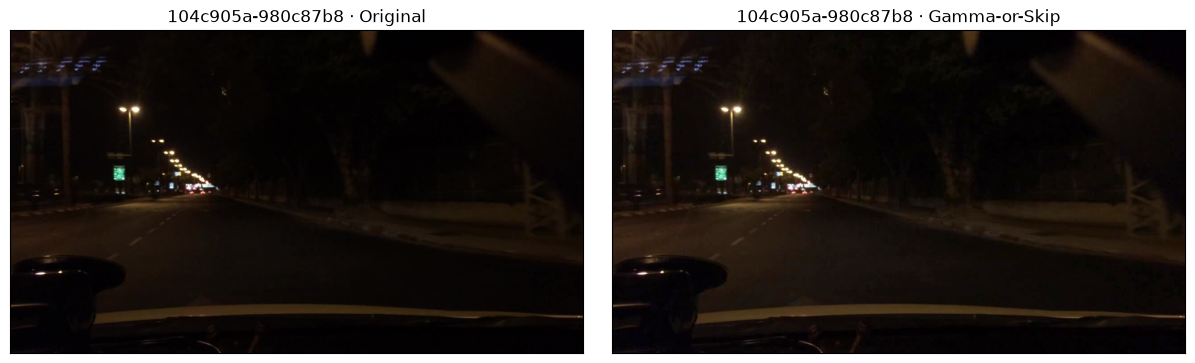

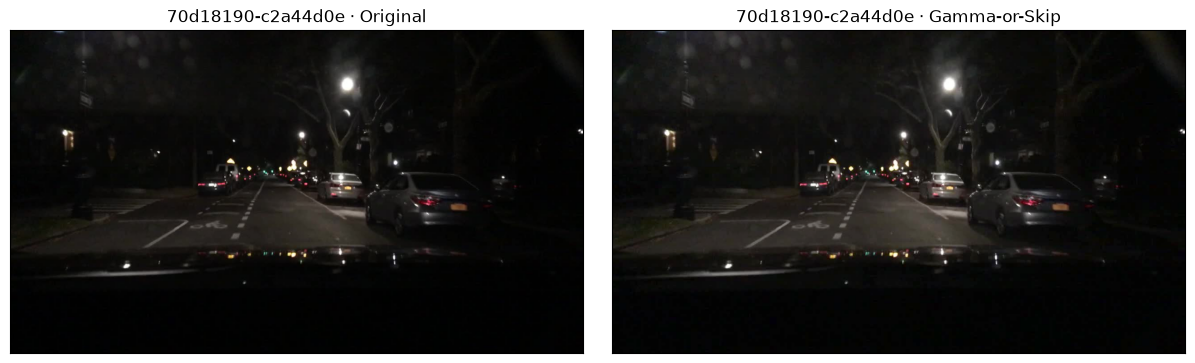

In [2]:
calibration = [r for r in rows if r["role"] == "calibration"]
picked = np.random.default_rng(config["seed"]).choice(len(calibration), SAMPLES, replace=False)
records, pairs = [], []
for index in picked:
    row = calibration[index]
    image = read_image(data_root / row["source_path"])
    start = time.perf_counter()
    output, applied, scores = apply_recipe(image, config["variant"], config["recipes"])
    elapsed = (time.perf_counter() - start) * 1000
    records.append(
        {"id": row["id"], "applied": "+".join(a["name"] for a in applied), "ms": elapsed, **scores}
    )
    if applied and len(pairs) < SHOW:
        pairs.append((row["id"], image, output))
preview = pd.DataFrame(records)
display(
    preview.groupby("applied", dropna=False).agg(
        images=("id", "size"),
        ms=("ms", "mean"),
        brightness=("brightness", "mean"),
        contrast=("contrast", "mean"),
    )
)
for sample_id, before, after in pairs:
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), layout="constrained")
    for ax, image, label in zip(axes, (before, after), ("Original", config["name"]), strict=True):
        ax.imshow(image[:, :, ::-1])
        ax.set(title=f"{sample_id} · {label}", xticks=[], yticks=[])
    plt.show()

<a id="section-3"></a>

## 3. Policy Summary

In [3]:
print("Variant:", config["variant"], "| Recipes:", config["recipes"])
print(f"Applied to {(preview.applied != '').mean():.1%} of {len(preview)} calibration samples")
print("Export happens only in 02_train_prepare; final-test pixels stay sealed.")

Variant: adaptive | Recipes: {'adaptive': {'brightness_below': 0.12, 'contrast_below': 0.0, 'max_filters': 1, 'noise_above': 1.0, 'sharpness_below': 0.0, 'sharpness_min': 0.0}, 'clahe': {'clip_limit': 1.2, 'grid_size': 8}, 'denoise': {'strength': 2.0}, 'gamma': {'gamma': 0.85}, 'raw': {}, 'sharpen': {'amount': 0.15, 'sigma': 1.0}}
Applied to 35.9% of 64 calibration samples
Export happens only in 02_train_prepare; final-test pixels stay sealed.


## Historical experiment lineage — v1

This notebook retains **all current preprocessing preview cells and their saved outputs**, while adding research experiment provenance from the pre-PR #55 repository. The historical protocols remain distinguishable from S20 full-finetuning and new cross-evaluation. Historical/failed-pilot claims cannot become new independent evidence. The final holdout is sealed, and no evaluation or training has been rerun.

Current training and native evaluation remain in `02_train_prepare`, `03_train`, `04_eval`; cross-policy comparison remains in `../compare.ipynb`. The archive below contains full historical Python procedure text but does **not** execute removed modules.

### Embedded historical results (readable without Git or external JSON)

Snapshot: `948e1d3fd5d7f1f745121fb1ad5063076a682884` (pre-PR #55). The 15 historical registry JSON files are absent from the current tree; the summaries below were transcribed from that pinned snapshot and its named reports. Percentages are AP50:95 unless stated; differences are percentage points (pp). No historical inference/training was rerun for this restoration. The final holdout remains sealed.

**Naming boundary:** historical “frozen v2” means Issue #6’s `issue6-policy-v2` Gamma-or-Skip; it is not today’s local-shadow `v2`. Historical frozen-backbone experiments are separate from current full fine-tuning.

#### v1-locked — Locked Gamma-or-Skip policy

The 256-image calibration sample supported Gamma 0.85 below brightness 0.12: 65 eligible images, 12 candidates, status `proxy_calibrated_filter`. CLAHE had only 5 candidates and Denoise/Sharpen had 0, so all three remained `uncalibrated_insufficient_support` and disabled. The noise proxy was zero on 229/256 images and remains unvalidated. This is proxy calibration, not a passed detection-benefit gate; no development or final outcome selected the recipe.

Provenance: [docs/issue6-v2/policy.json](https://github.com/truong51972/vehicle-detection/blob/948e1d3fd5d7f1f745121fb1ad5063076a682884/docs/issue6-v2/policy.json); [historical report](https://github.com/truong51972/vehicle-detection/blob/948e1d3fd5d7f1f745121fb1ad5063076a682884/docs/ISSUE6_REVIEW.md). JSON SHA256: `939ce2419171c68b41789a41cfe2b64b31f983eec4c749e6df8824663c7cec5f`.

#### v1-routing — Historical S10 routing and support

The deeply verified paired S10 export contains 4,890 images per branch: 1,107 Gamma and 3,783 Skip (77.36% skipped). All 1,107 transformed images improved the aggregate quality proxy; no detector or training ran. Adaptive preprocessing p50/p95 was 2.915/5.980 ms versus Raw diagnostic extraction 2.780/3.224 ms; these are offline CPU stages, not deployment latency. The export/support checks passed, but proxy gains do not establish AP improvement. Frozen S20 membership contains 9,781 images and includes S10.

Provenance: [docs/issue6-v2/summary.json](https://github.com/truong51972/vehicle-detection/blob/948e1d3fd5d7f1f745121fb1ad5063076a682884/docs/issue6-v2/summary.json); [historical report](https://github.com/truong51972/vehicle-detection/blob/948e1d3fd5d7f1f745121fb1ad5063076a682884/docs/ISSUE6_REVIEW.md). JSON SHA256: `ff51ccdf77ef38608bbaf9cb106e22321b37f158eb39fea847e4e105b3e660c4`.

#### v1-s10 — Six-class paired S10 training

Both branches trained the same 4,890 images for 20 epochs at 640, seed 2026, FP32 AdamW, frozen backbone 11 and no augmentation. These are historical six-class saved epoch metrics on Raw development inputs: pretrained AP50:95 13.6362%; best Raw 16.122% (epoch 4), Gamma-or-Skip 16.479% (epoch 6). The best-epoch difference was +0.357 percentage points; at epoch 20 it was only +0.035. Completion, matched budgets and artifact checks passed. One seed and selected epochs do not establish an independently confirmed policy advantage; the full matrix was still pending at this milestone.

Provenance: [docs/issue7/s10_results.json](https://github.com/truong51972/vehicle-detection/blob/948e1d3fd5d7f1f745121fb1ad5063076a682884/docs/issue7/s10_results.json); [historical report](https://github.com/truong51972/vehicle-detection/blob/948e1d3fd5d7f1f745121fb1ad5063076a682884/docs/ISSUE7_RESULTS.md). JSON SHA256: `1ee5ade5a28710451d5f8281dbea3773cc51b4026f27f98ab62bd2a4c51e0a11`.

#### v1-development — Five-class S10 development matrix

On 13,975 development images / 8,258 source groups with five-class GT, AP50:95 for Raw / Gamma-or-Skip inputs was: pretrained 16.182946% / 16.216251%; Raw-trained S10 19.075607% / 19.085975%; Gamma-trained S10 19.324790% / 19.363086%. Training contrasts were +0.2492 / +0.2771 points, with conditional 95% paired-group intervals [+0.0183, +0.4714] / [+0.0295, +0.4898]; all 100 draws per contrast were valid. These are descriptive reused-development, single-seed results, not confirmation or current S20/full-finetune results. Do not compare the five-class denominator with the six-class epoch results above as a new gain.

Provenance: [docs/development-five-v1/matrix.json](https://github.com/truong51972/vehicle-detection/blob/948e1d3fd5d7f1f745121fb1ad5063076a682884/docs/development-five-v1/matrix.json); [historical report](https://github.com/truong51972/vehicle-detection/blob/948e1d3fd5d7f1f745121fb1ad5063076a682884/docs/development-five-v1/RESULTS.md). JSON SHA256: `606b2a68b1ab2c660270f5ab8f7289a43c9a4c8141d325012de71559553ae352`.



## A. Study registry and saved evidence

Run the next cell to see each study, its dataset/population, archival evidence path and interpretation boundary. For detailed saved JSON evidence, run `inspect_saved_study("study-id")` manually. Historical git history is read-only. Missing evidence is reported as unavailable, not re-created or misreported as zero.

`inspect_saved_study()` needs Git installed and commit `948e1d3fd5d7f1f745121fb1ad5063076a682884` in the local repository to read the pinned JSON. Shallow clones may omit that commit, and downloaded ZIPs contain no Git history. The viewer then tries a local evidence file, labelled as an unverified revision; otherwise it reports evidence as unavailable. The embedded summaries above remain readable in either case.

Open the per-study pinned JSON links above (for example, [pinned evidence JSON](https://github.com/truong51972/vehicle-detection/blob/948e1d3fd5d7f1f745121fb1ad5063076a682884/docs/issue6-v2/policy.json)) without local Git history. To enable the viewer in a Git clone, run this manually from the repository root, then retry `inspect_saved_study()`:

```sh
git fetch origin 948e1d3fd5d7f1f745121fb1ad5063076a682884
```

For a downloaded ZIP, use the pinned links or clone the repository before fetching. The notebook never fetches history automatically.

In [4]:
# Historical experiment ledger — no training, inference or file writes
import json
import subprocess

import pandas as pd
from IPython.display import display

HISTORICAL_COMMIT = "948e1d3fd5d7f1f745121fb1ad5063076a682884"
RESEARCH_ROOT = ROOT  # Reuse the preview configuration and its prerequisite checks.
STUDIES = [
    {
        "id": "v1-locked",
        "provenance": "historical policy",
        "population": "Calibration; Gamma-or-Skip",
        "evidence": "docs/issue6-v2/policy.json",
        "boundary": "No policy retuning",
    },
    {
        "id": "v1-routing",
        "provenance": "historical calibration",
        "population": "Routing/support",
        "evidence": "docs/issue6-v2/summary.json",
        "boundary": "Original study population",
    },
    {
        "id": "v1-s10",
        "provenance": "historical training",
        "population": "Paired S10 detector",
        "evidence": "docs/issue7/s10_results.json",
        "boundary": "Not current S20",
    },
    {
        "id": "v1-development",
        "provenance": "historical evaluation",
        "population": "Five-class development",
        "evidence": "docs/development-five-v1/matrix.json",
        "boundary": "No independent confirmation",
    },
    {
        "id": "v1-current",
        "provenance": "current full-finetune",
        "population": "S20; YOLO26n full-finetune",
        "evidence": "notebooks/experiments/v1/04_eval.ipynb",
        "boundary": "Use current 02–04 lifecycle",
    },
]

display(
    pd.DataFrame(STUDIES).rename(
        columns={
            "id": "Study",
            "provenance": "Source",
            "population": "Population / design",
            "evidence": "Evidence file",
            "boundary": "Interpretation",
        }
    )
)


def archived_evidence(path):
    """Historical snapshot first; local copy only as a provenance-labelled fallback."""
    try:
        proc = subprocess.run(
            ["git", "-C", str(RESEARCH_ROOT), "show", f"{HISTORICAL_COMMIT}:{path}"],
            capture_output=True,
            check=False,
            timeout=20,
        )
        if proc.returncode == 0:
            return proc.stdout, f"commit {HISTORICAL_COMMIT[:12]}"
    except (OSError, subprocess.TimeoutExpired):
        pass
    local = RESEARCH_ROOT / path
    if local.is_file():
        return local.read_bytes(), "local file: verify revision"
    return None, "not available in local checkout"


def inspect_saved_study(study_id):
    """Display recorded evidence; never rerun acquisition or invent absent metrics."""
    s = next((item for item in STUDIES if item["id"] == study_id), None)
    if s is None:
        raise ValueError(f"Unknown study: {study_id}")
    print("Study:", s["id"], "|", s["population"])
    print("Boundary:", s["boundary"])
    path = s["evidence"]
    if path.endswith(".ipynb"):
        print("Active lifecycle notebook:", path)
        return
    raw, origin = archived_evidence(path)
    print("Evidence:", path, "|", origin)
    if raw is None:
        print("Missing saved evidence is NOT a zero metric or a failed study.")
        return
    if path.endswith(".json"):
        report = json.loads(raw.decode("utf-8"))
        if isinstance(report, dict):
            print("Saved fields:", list(report))
        display(report)
    elif path.endswith(".csv"):
        from io import BytesIO

        display(pd.read_csv(BytesIO(raw)).head(30))
    else:
        print(raw.decode("utf-8", errors="replace")[:12000])


# Inspect on demand, e.g. inspect_saved_study("v1-locked")

,Study,Source,Population / design,Evidence file,Interpretation
0,v1-locked,historical policy,Calibration; Gamma-or-Skip,docs/issue6-v2/policy.json,No policy retuning
1,v1-routing,historical calibration,Routing/support,docs/issue6-v2/summary.json,Original study population
2,v1-s10,historical training,Paired S10 detector,docs/issue7/s10_results.json,Not current S20
3,v1-development,historical evaluation,Five-class development,docs/development-five-v1/matrix.json,No independent confirmation
4,v1-current,current full-finetune,S20; YOLO26n full-finetune,notebooks/experiments/v1/04_eval.ipynb,Use current 02–04 lifecycle


## B. Archived full experiment procedures

Original notebook markdown and Python source are preserved in the following non-executable appendix. Source code may reference modules and evidence removed by PR #55; code is intentionally quoted rather than run. 

### 1. 01_experiments.ipynb

**Historical study — non-executable source archive.** [Original notebook at pinned pre-refactor commit](https://github.com/truong51972/vehicle-detection/blob/948e1d3fd5d7f1f745121fb1ad5063076a682884/notebooks/experiments/v1/01_experiments.ipynb). Original procedure, code, acquisition flags, cohorts, uncertainty and interpretation are reproduced below; old dependencies removed in PR #55 are **not imported or executed**.

**Original cell 1 — study narrative**

#### 01 — Historical Gamma-or-Skip Policy

Inspect the frozen calibration-only Gamma-or-Skip policy and its observed routing. This is historical exploration evidence, not a policy recalibration.

**Inputs:** docs/issue6-v2/policy.json and routing support.

**Outputs:** Read-only display; no policy or detector changes.

**Prerequisites:** Committed historical evidence; new policy parameters require a new experiment ID.

**Outline**

- [1. Configuration](#section-1)
- [2. Locked Policy](#section-2)
- [3. Policy Summary](#section-3)

**Original cell 2 — study narrative**

##### 1. Configuration

Folder v1 is an experiment identity. The original algorithm label is Adaptive v2.

**Original cell 3 — Python source (archived, not run)**

```python
from pathlib import Path

import pandas as pd
from IPython.display import display

from vehicle_detection.common import read_json, require_paths

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
POLICY = ROOT / "docs/issue6-v2/policy.json"
require_paths(policy=POLICY)
policy = read_json(POLICY)
```

**Original cell 4 — study narrative**

##### 2. Locked Policy

Brightness below 0.12 selects Gamma 0.85; all other pixels use Skip. Quality scores use the preserved maximum-512-side scale.

**Original cell 5 — Python source (archived, not run)**

```python
display(pd.DataFrame([policy["recipes"]["adaptive"]]))
print("Gamma:", policy["recipes"]["gamma"])
print("Historical policy ID:", policy["policy_id"])
display(pd.read_csv(ROOT / "docs/issue6-v2/subset_support.csv").head())
```

**Original cell 6 — study narrative**

##### 3. Policy Summary

The paired detector completed S10 training. No new policy is frozen by reading this notebook.

**Original cell 7 — Python source (archived, not run)**

```python
print("Locked for paired S10 training; evaluated historical evidence exists.")
print("Policy provenance: docs/ISSUE6_RESULTS.md and docs/ISSUE6_REVIEW.md")
print("Training: docs/ISSUE21_RESULTS.md")
print("Evaluation: docs/development-five-v1/RESULTS.md")
```



### Current lifecycle boundary

The original seven preview cells remain first, unchanged from `main`, including source, saved outputs and execution metadata. Current S20 preparation, training and native evaluation belong in `02_train_prepare`, `03_train` and `04_eval`; cross-policy comparisons belong in `../compare.ipynb`. Historical results above do not validate the current full-finetune recipe.

**Historical studies are archived, read-only evidence and procedures, not runnable or fully reproducible experiments in this checkout.** Some legacy modules and evidence paths were removed. **Current studies are executable through the maintained [02_train_prepare](02_train_prepare.ipynb) → [03_train](03_train.ipynb) → [04_eval](04_eval.ipynb) lifecycle**, with each expensive stage requiring its explicit opt-in. Running that lifecycle produces a new current study; it does not reproduce the archived historical studies.